# 6 - Purity and Depth Adjustment Diagnostics

**Purpose**: Validates the CIDER Score purity and sequencing-depth normalisation.
Shows raw vs adjusted scatter (coloured by purity), cohort distribution shift,
and correlation with purity/depth before and after adjustment.

| | |
|---|---|
| **Inputs** | `CIDER_PROJ_DIR/cpi_ready.rds` |
| **Outputs** | `figs/adjustment_diagnostic.png`, `figs/confounders_supplement.png` |

In [1]:
source(paste0(dirname(getwd()), "/helpers/map.r"))
source(paste0(dirname(getwd()), "/helpers/shortcuts.r"))
source(paste0(dirname(getwd()), "/helpers/config.r"))
source(paste0(dirname(getwd()), "/helpers/themes.r"))

# Ensure figures output directory exists
dir.create(paste0(CIDER_PROJ_DIR, "figs/"), showWarnings = FALSE, recursive = TRUE)

In [2]:
library(ggpubr)
library(patchwork)

# 0 - Read data

In [ ]:

# cider_score_depth_adj = depth-normalised only (ImmuneLENS-comparable baseline)
# cider_score_adj       = depth + purity normalised (integrated pipeline advantage)
ready_wide <-
  readRDS(paste0(CIDER_PROJ_DIR, "ready.rds")) |>
  filter(gp == "T-cell") |>
  select(sampleId, gp, purity, sampleMedianDepth,
         cider_score, cider_score_depth_adj, cider_score_adj)

# Long format: depth-adj as "before", purity+depth-adj as "after"
ready_long <- ready_wide |>
  pivot_longer(
    cols      = c(cider_score_depth_adj, cider_score_adj),
    names_to  = "estimate",
    values_to = "value"
  ) |>
  mutate(estimate = factor(
    ifelse(estimate == "cider_score_depth_adj",
           "CIDER Score",
           "CIDER Score (Purity Adjusted)"),
    levels = c("CIDER Score", "CIDER Score (Purity Adjusted)")
  ))

# 1 - Adjustment diagnostic

Four-panel figure validating the purity correction:

- **A** Scatter of unadjusted vs adjusted, coloured by purity — shows which samples are most affected and confirms the correction moves high-purity samples upward as expected.
- **B** Paired boxplots per cohort — reveals differential shifting across cohorts driven by their purity distributions.
- **C / D** Pearson correlation with purity before and after adjustment — the r value should drop substantially after correction if the formula is working.

In [ ]:
# Figure 1C: Purity correction — the integrated pipeline advantage.
#
# Starting from the depth-normalised score (comparable to ImmuneLENS), we show:
#   A — residual purity correlation that persists after depth correction alone
#   B — purity correlation eliminated after adding the PURPLE-derived correction
#   C — how purity correction moves individual samples (scatter, coloured by purity)
#   D — differential cohort shifts: BLCA (lower purity) shifts more than SKCM

# ── Panel A: depth-adj CIDER Score vs purity (residual correlation) ──────────
p_corr_depth <- ready_wide |>
  filter(gp == "T-cell") |>
  ggplot(aes(x = purity, y = cider_score_depth_adj)) +
  geom_point(alpha = 0.4, size = 0.8) +
  scale_y_continuous(trans = log10p1_trans) +
  # Generic single-series trend-line accent (no categorical meaning) --
  # COL_ACCENT, matching the same helper trend-line colour used below.
  geom_smooth(method = "lm", colour = COL_ACCENT) +
  stat_cor(aes(label = after_stat(r.label)), method = "pearson", label.x.npc = "left", label.y = Inf, vjust = 1.3, size = 4) +
  go_theme +
  labs(x = "Tumour Purity", y = "CIDER T-cell Score",
       title = "Residual Purity Correlation")

# ── Panel B: purity+depth CIDER Score vs purity (correction applied) ─────────
p_corr_adj <- ready_wide |>
  filter(gp == "T-cell") |>
  ggplot(aes(x = purity, y = cider_score_adj)) +
  geom_point(alpha = 0.4, size = 0.8) +
  scale_y_continuous(trans = log10p1_trans) +
  # Distinct from Panel A's trend line (COL_ACCENT) so the "before" vs
  # "after" correction panels remain visually distinguishable; COL_MID
  # (closest surviving green-family colour to the old purple) rather than
  # reusing COL_ACCENT.
  geom_smooth(method = "lm", colour = COL_MID) +
  stat_cor(aes(label = after_stat(r.label)), method = "pearson", label.x.npc = "left", label.y = Inf, vjust = 1.3, size = 4) +
  go_theme +
  labs(x = "Tumour Purity", y = "CIDER T-cell Score (Purity + Depth Adjusted)",
       title = "Purity Correlation Attenuated")

# ── Panel C: scatter depth-adj vs purity+depth-adj coloured by purity ────────
p_scatter <- ready_wide |>
  filter(gp == "T-cell") |>
  ggplot(aes(x = cider_score_depth_adj, y = cider_score_adj, colour = purity)) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = COL_NEGATIVE) +
  geom_point(alpha = 0.6, size = 1.2) +
  scale_x_continuous(trans = log10p1_trans) +
  scale_y_continuous(trans = log10p1_trans) +
  # Continuous purity gradient: COL_INK (was "black") at the low end,
  # COL_NEGATIVE (was "grey92") at the high end -- the two approved
  # ink/muted-grey constants rather than a literal grey hex.
  scale_colour_gradient(low = COL_INK, high = COL_NEGATIVE, name = "Purity") +
  go_theme +
  labs(x = "CIDER T-cell Score", y = "CIDER T-cell Score (Purity Adjusted)",
       title = "High-Purity Samples Shift Most")

saveRDS(p_scatter,    paste0(CIDER_PROJ_DIR, "figs/purity_scatter.rds"))


`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


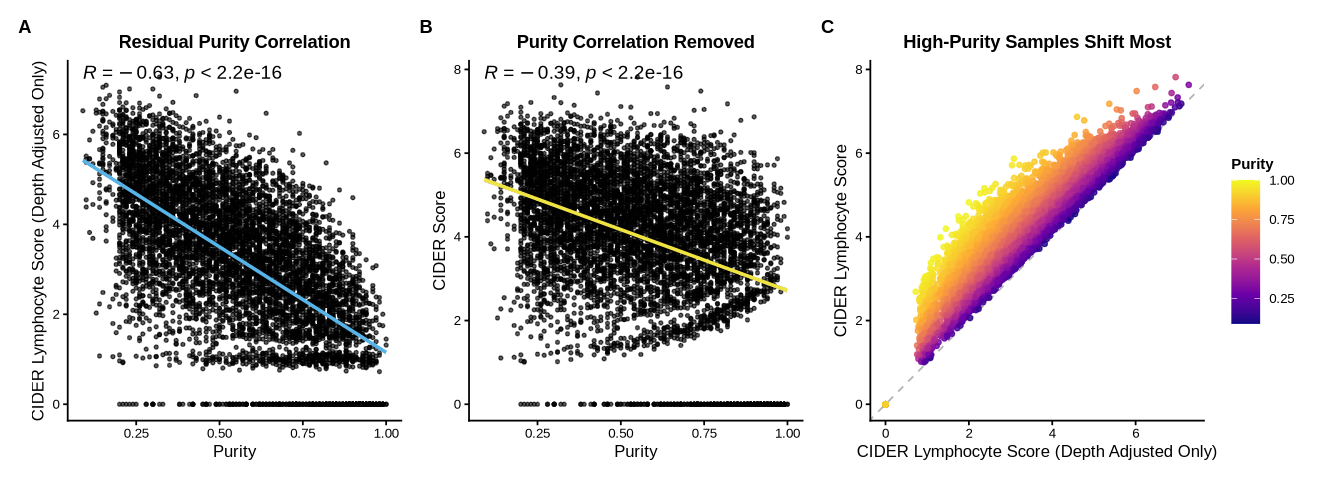

In [5]:
# ── Compact 3-panel version for Figure 2C ────────────────────────────────────
# E: purity correlation after depth correction (residual signal)
# F: purity correlation after purity+depth correction (removed)
# G: scatter depth-adj vs purity+depth-adj coloured by purity
adjustment_diagnostic_compact <-
  (p_corr_depth | p_corr_adj | p_scatter) +
  figure_annotation(tag = TRUE)

set_plot_dims(11, 4); adjustment_diagnostic_compact

# 2 - Confounder supplement: purity and depth vs unadjusted CIDER score

In [ ]:
# ── Shared helper ─────────────────────────────────────────────────────────────
# Scatter of cider_score (T-cell) against any continuous confounder. Used
# for both purity and sequencing depth panels.
confounder_scatter <- function(data, x_col, x_lab, title) {
  data |>
    ggplot(aes(x = .data[[x_col]], y = cider_score)) +
    geom_point(alpha = 0.3, size = 0.8) +
    # Generic single-series trend-line accent (no categorical meaning) --
    # COL_ACCENT, shared with the Panel A trend line above.
    geom_smooth(method = "lm", colour = COL_ACCENT) +
    stat_cor(
      method = "pearson",
      label.x.npc = "left", label.y = Inf, vjust = 1.3,
      size = 3
    ) +
    go_theme +
    scale_y_continuous(trans = log10p1_trans) +
    labs(x = x_lab, y = "CIDER Raw Score", title = title) +
    tags_supp
}

`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


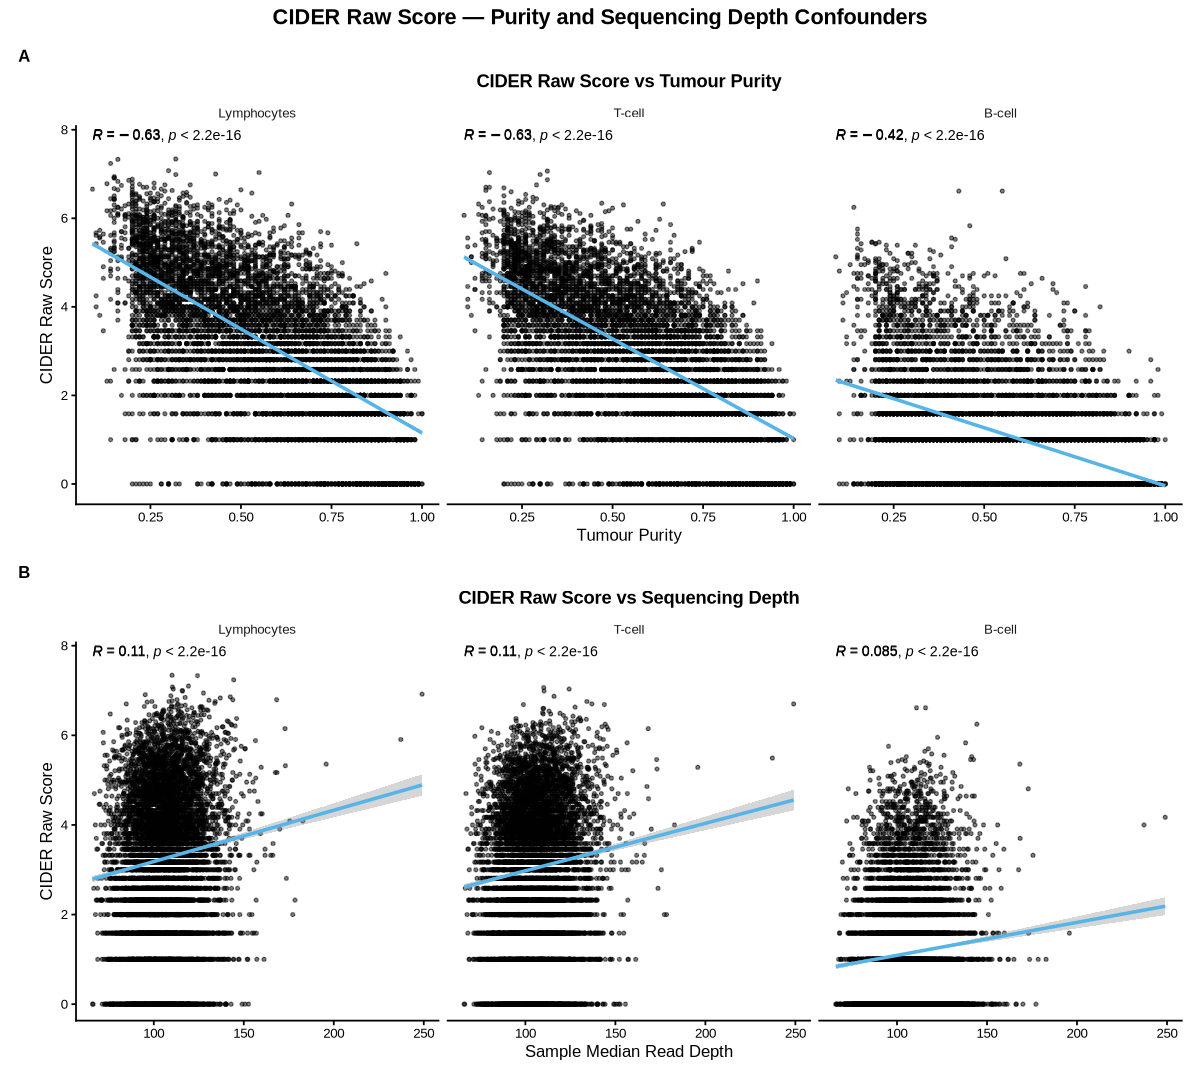

In [7]:
# Two-panel supplement: purity (left) and sequencing depth (right).
# Motivates the double adjustment in cider_score_adj.
p_purity_all <- confounder_scatter(
  ready_wide,
  x_col = "purity",
  x_lab = "Tumour Purity",
  title = "CIDER Raw Score vs Tumour Purity"
)

p_depth_all <- confounder_scatter(
  ready_wide,
  x_col = "sampleMedianDepth",
  x_lab = "Sample Median Read Depth (log scale)",
  title = "CIDER Raw Score vs Sequencing Depth"
) + scale_x_continuous(trans = log10p1_trans)

confounders_supplement <-
  (p_purity_all / p_depth_all) +
  figure_annotation("CIDER Raw Score — Purity and Sequencing Depth Confounders")

saveRDS(confounders_supplement, paste0(CIDER_PROJ_DIR, "figs/confounders_supplement.rds"))
set_plot_dims(10, 9); confounders_supplement

# 3 - Low Purity Prevalence: CPI vs Non-CPI

Tests the hypothesis that ICI-treated patients have higher rates of low-purity
samples (WARN_LOW_PURITY) compared to the broader Hartwig cohort, reflecting
greater immune infiltration diluting tumour cellularity.

In [ ]:
# Read full meta_base — contains all samples with QCStatus and cpi flag
meta_all <- fread(paste0(CIDER_PROJ_DIR, "meta_base.csv")) |>
  distinct(sampleId, cpi, QCStatus) |>
  mutate(
    group       = ifelse(cpi, "ICI-Treated", "Non-ICI"),
    low_purity  = QCStatus == "WARN_LOW_PURITY"
  )

# Compute % low purity per group with 95% CI (Wilson)
low_purity_summary <- meta_all |>
  group_by(group) |>
  summarise(
    n          = n(),
    n_low      = sum(low_purity, na.rm = TRUE),
    pct        = n_low / n * 100,
    ci_low     = 100 * (prop.test(n_low, n)$conf.int[1]),
    ci_high    = 100 * (prop.test(n_low, n)$conf.int[2]),
    .groups    = "drop"
  )

# Fisher's exact test
ct <- with(meta_all, table(group, low_purity))
p_fisher <- fisher.test(ct)$p.value
p_label  <- fmt_pval(p_fisher)

message("Low purity prevalence:")
print(low_purity_summary)
message("Fisher exact test: ", p_label)

In [ ]:
low_purity_plot <- low_purity_summary |>
  ggplot(aes(x = group, y = pct, fill = group)) +
  geom_col(alpha = 0.85, width = 0.5) +
  geom_errorbar(aes(ymin = ci_low, ymax = ci_high), width = 0.15, linewidth = 0.7) +
  geom_text(aes(label = paste0(round(pct, 1), "%")),
            vjust = -0.5, size = 3.5, fontface = "bold") +
  annotate("text", x = 1.5, y = max(low_purity_summary$ci_high) * 1.15,
           label = p_label, size = 3.5, hjust = 0.5) +
  # Binary, non-Responder-like contrast (rule 3): "ICI-Treated" is the
  # notable/exceptional group being highlighted here (low-purity
  # prevalence) -> COL_ACCENT; "Non-ICI" is the baseline/reference
  # group -> COL_NEGATIVE.
  scale_fill_manual(values = c("ICI-Treated" = COL_ACCENT, "Non-ICI" = COL_NEGATIVE),
                    guide = "none") +
  scale_y_continuous(expand = expansion(mult = c(0, 0.20))) +
  go_theme +
  labs(
    x     = NULL,
    y     = "Samples with Low Purity (%)",
    title = "Low Purity Prevalence: ICI-Treated vs Non-ICI Patients"
  )

set_plot_dims(5, 5); low_purity_plot